# 03 · Features and validation design
**Project:** Next-day PM2.5 exceedance alerts for Chennai · CS3006 · pipeline stage **5 Features**

Stage 4 (notebook 02) produced hypotheses backed by evidence. This notebook turns them into
model inputs and fixes **how models will be validated**, before any model is trained:

1. the feature set, each feature traced to its EDA evidence,
2. missing inputs and how they are filled (inside the model pipeline, fitted on training rows only),
3. near-duplicate features,
4. an **automated leakage test**: proof that no feature uses data from after day D,
5. the cross-validation design inside the training years.

All feature code lives in `src/features.py`. Like notebook 02, every analysis here uses the
training years (2021-23) only.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))      # run from the notebooks/ folder

import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.metrics import average_precision_score

from src import config as C, eda, features as F
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 80)
np.random.seed(C.RANDOM_SEED)

def show(fig_path):
    display(Image(str(fig_path)))

## 1 · The feature set
**Rule:** every feature must be computable at the end of day D. Pollution and weather come
from day D or earlier. The only things about day D+1 are **calendar facts known in advance**:
which month tomorrow is, and whether tomorrow is Diwali or Bhogi.

In [2]:
info = pd.DataFrame(F.FEATURE_INFO, index=["group", "meaning", "EDA evidence (notebook 02)"]).T
info.index.name = "feature"
print(len(F.FEATURES), "features")
info

22 features


,group,meaning,EDA evidence (notebook 02)
feature,,,
st_Manali,station,1 if the row is Manali,station medians differ (§1); one pooled model (§2)
st_Kodungaiyur,station,1 if the row is Kodungaiyur,station medians differ (§1); one pooled model (§2)
st_Arumbakkam,station,1 if the row is Arumbakkam,station medians differ (§1); one pooled model (§2)
st_Perungudi,station,1 if the row is Perungudi,station medians differ (§1); one pooled model (§2)
log_pm25,persistence,log of today's PM2.5,H2: 56% vs 3% (§4)
log_pm25_change,persistence,log PM2.5 today minus yesterday (rising or falling?),onset days missed by persistence (§4)
log_pm25_roll3,persistence,mean log PM2.5 over the last 3 days,lag correlations stay > 0.5 for 3 days (§4)
log_pm25_roll7,persistence,mean log PM2.5 over the last 7 days,correlation fades over a week (§4)
pm25_missing,persistence,1 if today's PM2.5 is missing (then filled in),missing values are not random (§2)


**Choices worth defending**
* **Logs for PM2.5 and rain.** Both are right-skewed (notebook 02 §1). On a log scale, a jump from
  20 to 40 counts the same as one from 40 to 80, which matches how pollution builds up.
* **Month as a circle (sin, cos).** As a plain number, December (12) and January (1) would look
  far apart, but they are neighbours in the polluted season. Two coordinates on a circle fix that.
* **City-wide mean of the *other* stations.** It uses only the others, so it is a separate signal
  from the station's own reading. On days when the own sensor is down, it is the best available stand-in.
* **Left out on purpose:** weekday (§8, p = 0.40); boundary-layer height (§7: a proxy for the air
  mass, and Open-Meteo has none for Jan-Jun 2024); temperature (§7: mostly the season, and tied to
  dew point); other pollutants (not studied in the EDA, so adding them now would be fishing).

In [3]:
feats = F.make_features()
tr = F.model_rows(feats, "train")
print("feature table:", feats.shape, "| labelled training rows:", len(tr), "| positives:", int(tr.y.sum()))
tr[["date", "station", "y"] + F.FEATURES[4:12]].head()

feature table: (8576, 36) | labelled training rows: 3506 | positives: 215


,date,station,y,log_pm25,log_pm25_change,log_pm25_roll3,log_pm25_roll7,pm25_missing,city_log_pm25,month_sin,month_cos
0,2021-01-01,Manali,0.0,3.772301,NaN,NaN,NaN,0.0,3.933828,0.0,1.0
1,2021-01-02,Manali,0.0,3.704507,-0.067794,3.738404,NaN,0.0,3.903849,0.0,1.0
2,2021-01-03,Manali,0.0,3.559340,-0.145167,3.678716,NaN,0.0,3.606598,0.0,1.0
3,2021-01-04,Manali,0.0,3.549905,-0.009435,3.604584,3.646513,0.0,3.308755,0.0,1.0
4,2021-01-05,Manali,0.0,3.488903,-0.061002,3.532716,3.614991,0.0,2.758262,0.0,1.0


### A first look: how much does each feature say on its own?
PR-AUC of each single feature on the training years (the direction is chosen on the same data,
so treat these as *descriptive*, not as model scores). A feature with no information scores
the base rate, **0.061**.

In [4]:
rows = []
for col in F.FEATURES:
    d = tr[[col, "y"]].dropna()
    up, down = average_precision_score(d.y, d[col]), average_precision_score(d.y, -d[col])
    rows.append({"feature": col, "group": F.FEATURE_INFO[col][0], "PR-AUC alone": max(up, down),
                 "higher value means": "more risk" if up >= down else "less risk"})
single = pd.DataFrame(rows).sort_values("PR-AUC alone", ascending=False).set_index("feature")
single.round(3)

,group,PR-AUC alone,higher value means
feature,,,
log_pm25,persistence,0.503,more risk
city_log_pm25,city-wide,0.390,more risk
log_pm25_roll3,persistence,0.322,more risk
wind_v,weather D,0.226,less risk
log_pm25_roll7,persistence,0.226,more risk
dewpoint,weather D,0.156,less risk
pressure,weather D,0.144,more risk
log_pm25_change,persistence,0.131,more risk
month_sin,season,0.126,less risk


Today's PM2.5 alone reaches 0.50 (eight times the base rate), then come the city-wide mean and
the 3-day mean. Weather features are weak *on their own* (0.07-0.23). That is expected:
notebook 02 showed their effect depends on the season (humidity is near the base rate overall,
but r = −0.47 within winter). A model that combines them with month can use them. A single-feature
score cannot. **This is why weak features are not dropped just because they look weak alone.**

## 2 · Missing inputs

In [5]:
miss = pd.DataFrame({s: F.model_rows(feats, s)[F.FEATURES].isna().sum()
                     for s in ["train", "val", "test", "monitor"]})
miss = miss[miss.sum(axis=1) > 0]
miss.loc["labelled rows"] = [len(F.model_rows(feats, s)) for s in miss.columns]
miss

,train,val,test,monitor
log_pm25,40,7,29,17
log_pm25_change,80,14,57,34
log_pm25_roll3,40,6,31,14
log_pm25_roll7,48,4,27,16
city_log_pm25,11,2,0,15
dewpoint,0,0,0,20
rh,0,0,0,20
log_rain,0,0,0,20
log_rain_3d,0,0,0,20
pressure,0,0,0,20


**Decision: keep these rows and fill the gaps inside the model pipeline.**
* Any one feature is missing on 0-5% of rows (worst case: the 1-day change in the test year,
  57 of 1,210). Dropping them would mean the alert system goes silent
  whenever a sensor blips, which is not acceptable for a public-health tool.
* Gaps are filled with the **median of the training rows** (`SimpleImputer`), and
  `pm25_missing` tells the model when today's value was filled in, since missingness was not
  random (notebook 02 §2).
* `log_pm25_change` has twice as many gaps because it needs *two* days.
* The last monitoring rows lack weather: the Open-Meteo archive runs about 7 days behind.

The imputer sits *inside* each model's pipeline, so in cross-validation it is re-fitted on each
fold's training part. Proof:

In [6]:
folds = F.cv_folds(tr)
fit_rows, _ = folds[0]
pre = F.preprocessor(scale=True).fit(tr.iloc[fit_rows][F.FEATURES])
check = pd.DataFrame({
    "imputer value (fold 1)": pre.named_steps["impute"].statistics_,
    "median of fold-1 training rows (2021)": tr.iloc[fit_rows][F.FEATURES].median().to_numpy(),
    "median of all training rows (2021-23)": tr[F.FEATURES].median().to_numpy()},
    index=F.FEATURES).loc[["log_pm25", "log_pm25_change", "city_log_pm25", "dewpoint"]]
check.round(4)

,imputer value (fold 1),median of fold-1 training rows (2021),median of all training rows (2021-23)
log_pm25,3.0718,3.0718,3.1017
log_pm25_change,0.0040,0.0040,0.0031
city_log_pm25,3.0195,3.0195,3.0819
dewpoint,23.2458,23.2458,23.1875


The fill-in values equal the 2021 medians, not the 2021-23 medians. The fold-1 model never sees
anything from its validation year, not even through the preprocessing.

## 3 · Near-duplicate features

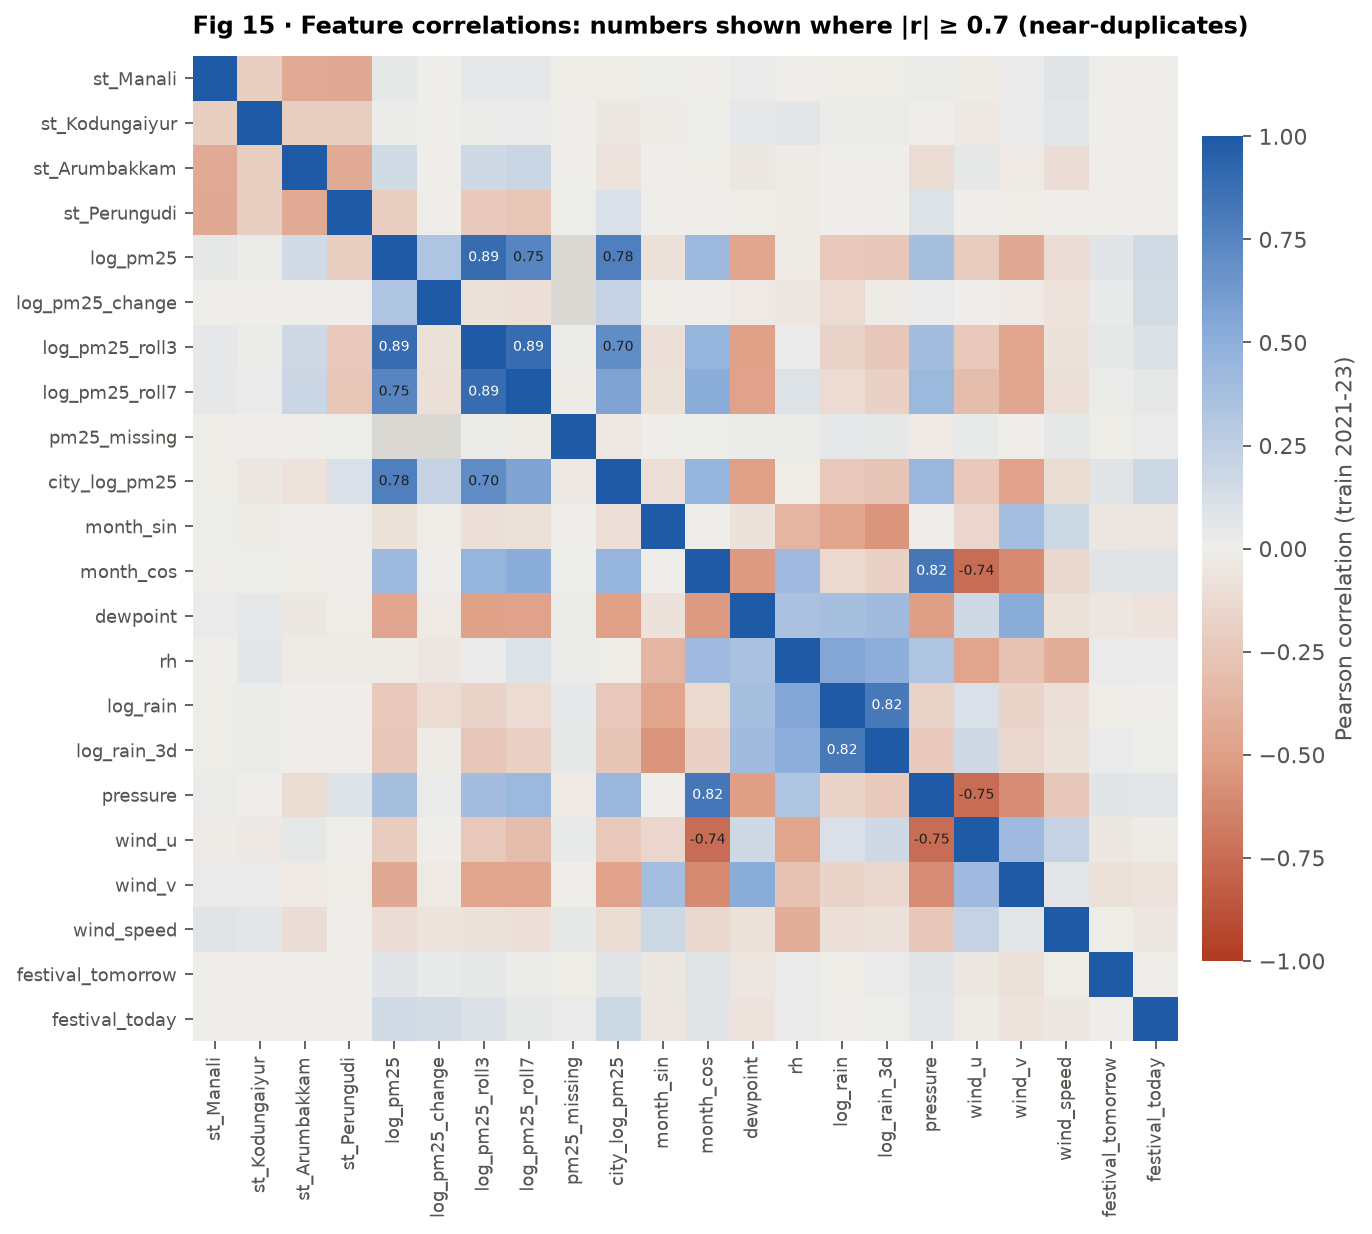

,feature A,feature B,r
0,log_pm25,log_pm25_roll3,0.89
1,log_pm25,log_pm25_roll7,0.75
2,log_pm25,city_log_pm25,0.78
3,log_pm25_roll3,log_pm25_roll7,0.89
4,log_pm25_roll3,city_log_pm25,0.70
5,month_cos,pressure,0.82
6,month_cos,wind_u,-0.74
7,log_rain,log_rain_3d,0.82
8,pressure,wind_u,-0.75


In [7]:
show(eda.fig_feature_corr(tr, F.FEATURES))
c = tr[F.FEATURES].corr()
pairs = [(a, b, c.loc[a, b]) for i, a in enumerate(F.FEATURES) for b in F.FEATURES[i + 1:]
         if abs(c.loc[a, b]) >= 0.7]
pd.DataFrame(pairs, columns=["feature A", "feature B", "r"]).round(2)

**What to do with them**
* **PM2.5 today / 3-day / 7-day / city-wide (0.70-0.89):** related but not the same. The
  difference between today and the 3-day mean is what tells the model whether pollution is
  *building up*.
* **Pressure, wind u and month cosine (0.74-0.82):** in Chennai, higher pressure and easterly winds
  *are* the winter. Within a season they still differ (notebook 02 §7: pressure keeps r = +0.30).
* **Rain today vs 3-day rain (0.82):** expected, since one contains the other.

**Decision: keep all of them for now.** The logistic regression in stage 6 uses an L2 penalty,
which shares weight between correlated features instead of letting coefficients blow up. Trees
just pick one of the pair. The cost is interpretation: in a model with correlated inputs, one
coefficient on its own cannot be read as "the effect of pressure". The report will say so.

## 4 · Leakage test: can any feature see the future?
Leakage means a model is given something it would not have when the forecast is made. Here that
means anything measured on D+1. A careful reading of the code is one check. A **test** is stronger:

> For a cut-off date, multiply every pollution and weather value **after** the cut-off by random
> numbers (0.2× to 5×), rebuild every feature, and compare all rows dated **on or before** the
> cut-off. If a single feature value changes, it was using future data.

As a positive control, the *target* (tomorrow's PM2.5) and the upper-bound D+1 weather on the
cut-off day **must** change. That proves the scrambling actually took effect.

In [8]:
leak = F.leakage_check()
assert (leak["main features changed"] == 0).all(), "a feature uses future data!"
assert (leak["targets changed (expected > 0)"] > 0).all()
leak

,cut-off,rows checked (date <= cut-off),main features changed,features that changed,targets changed (expected > 0),D+1 weather changed (expected > 0)
0,2022-06-30,2184,0,none,3,4
1,2023-11-15,4196,0,none,3,4
2,2024-12-15,5780,0,none,3,4
3,2025-10-19,7012,0,none,2,4


**Passed:** at four cut-offs spread over 2022-2025, 0 feature values changed on the 2,184-7,012
earlier rows. The targets and the D+1 weather did change, as they should. This test reruns every
time the notebook runs, so a future edit to `src/features.py` that leaks will fail loudly.

## 5 · Cross-validation design (for tuning in stage 6)

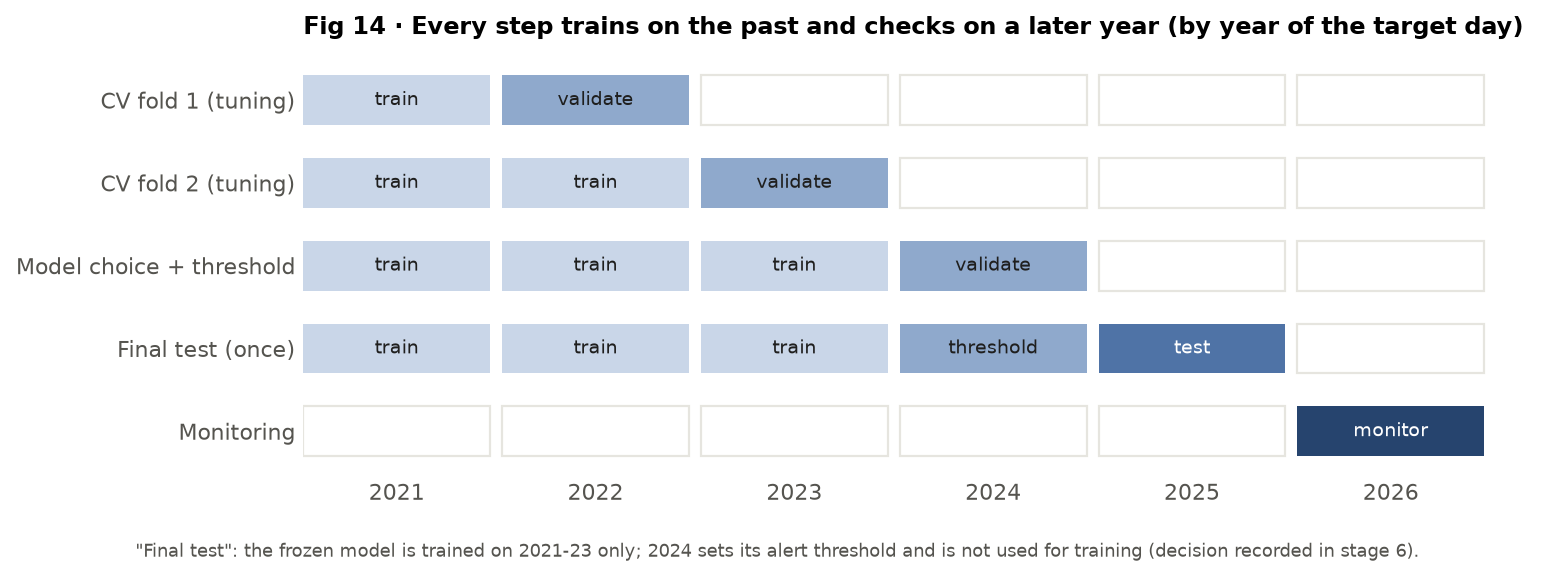

,train on (target years),validate on,train rows,train positives,validation rows,validation positives
fold,,,,,,
1,[2021],[2022],1367,74,1075,67
2,"[2021, 2022]",[2023],2442,141,1064,74


In [9]:
show(eda.fig_cv_timeline())
pd.DataFrame([{"fold": i + 1,
               "train on (target years)": sorted(set(tr.target_date.dt.year.iloc[a])),
               "validate on": sorted(set(tr.target_date.dt.year.iloc[b])),
               "train rows": len(a), "train positives": int(tr.y.iloc[a].sum()),
               "validation rows": len(b), "validation positives": int(tr.y.iloc[b].sum())}
              for i, (a, b) in enumerate(folds)]).set_index("fold")

**Forward-chaining, one whole year per validation fold.**
* **Why not ordinary shuffled k-fold?** Neighbouring days are near-copies (lag-1 r ≈ 0.76). With
  shuffling, a model would be validated on 14 March after training on 13 and 15 March, and the score
  would be too good. It would also train on 2023 to predict 2021, i.e. use the future.
* **Why whole years?** Nearly all positives are in Oct-Feb (notebook 02 §3). A fold that holds only
  part of a year could contain almost no bad days and give a meaningless score.
* **Why only two folds?** Three training years allow two forward steps. Each validation year
  still has 67-74 positives. Because the CV estimate rests on two numbers, stage 6 will tune only
  a few settings per model (e.g. regularisation strength). Searching a large grid on two folds
  would overfit the folds themselves.
* **Then 2024 as the single hold-out** for comparing the tuned models and choosing the alert
  threshold. 2025 stays untouched until the final test.

**Is there leakage at fold boundaries?** No. A validation row on 1 Jan 2022 uses PM2.5 from late
December 2021 as an *input*, which a real forecaster would also have. Labels never cross,
because rows are assigned by the year of the target day.

## 6 · Upper-bound feature set (kept separate)
`F.NEXT_DAY_FEATURES` holds the same weather measured on **D+1**. It answers one question in
stage 7: *how much better would the alerts be with a perfect weather forecast?* It is **never**
part of the main model, because at the end of day D tomorrow's weather is not known (it could only
come from a forecast, which has its own errors).

In [10]:
print(F.NEXT_DAY_FEATURES)
print("Correlation of today's vs tomorrow's dew point (train):",
      round(tr[["dewpoint", "next_dewpoint"]].corr().iloc[0, 1], 2))

['next_dewpoint', 'next_rh', 'next_pressure', 'next_wind_u', 'next_wind_v', 'next_wind_speed', 'next_log_rain']
Correlation of today's vs tomorrow's dew point (train): 0.92


## 7 · Summary: hand-off to stage 6

| Item | Decision |
|---|---|
| Features | 22 (4 station, 6 PM2.5/persistence, 2 season, 8 weather, 2 calendar), all known by the end of day D |
| Missing inputs | ≤ 5% of rows per feature; median fill + missing flag, inside the pipeline |
| Correlated features | kept; L2 penalty for logistic regression; caveat on reading coefficients |
| Leakage | automated test passes at 4 cut-offs |
| Tuning | forward-chaining CV, folds 2021→2022 and 2021-22→2023, small grids only |
| Hold-out | 2024 for model choice and threshold; 2025 once, at the end |
| Upper bound | D+1 weather set, reported separately in stage 7 |

**Next:** `04_models.ipynb` (stage 6): the "never alert" and persistence baselines, then logistic
regression (class-weighted, L2) and gradient-boosted trees, tuned on these folds, compared on
2024 by PR-AUC and recall at the chosen threshold.